# Managing Optical Datasets

In this session, we are going to continue our exploration of multispectral satlelite data that we began at the end of last week. 

Last week, we loaded a Landsat image of Bristol that had been pre-prepared for us (e.g. clipped to our region of interest and arranged into a single neat GeoTIFF file). However, when we are searching for our own satellite data, it is not this simple.

I have provided a complete Landsat image I downloaded from [the USGS EarthExplorer data browser](https://earthexplorer.usgs.gov/). Once you have registered for an account, this resource is the best online source for free download of Landsat data (and a multitude of other datasets). I will show you a Pythonic way to search and download data later in the session, but if you prefer to use a web-based graphical user interface, you are more than welcome to use the USGS EarthExplorer for this course. The search functionality is pretty self-explanatory, allowing you to search for a given geographic region, filter by date and cloud cover, and search specific datasets (for our purposes, the Landsat Collection 2 Level-2 data will be our go-to option). [A very useful video tutorial is available at this link](https://www.usgs.gov/media/videos/how-use-usgs-earthexplorer-download-imagery), and [a written guide is available here](https://www.usgs.gov/media/files/earthexplorer-user-interface-help-document).

I have already done the hard part for you here, and pre-downloaded a Landsat scene. Due to the large file size of the complete scene (~600 MB), our raw data this week can be found as a `.zip` file on the course Blackboard site. Find and download it from the 'Week 5 Data' folder: it is called `LC08_L2SP_042034_20260609_20260613_02_T1.zip`.


## Examining the data structure


The data is a Landsat 8 scene centred on [the 'Mammoth Lakes' region of California](https://www.google.com/maps/place/Mammoth+Lakes,+CA+93546,+USA/@37.6287792,-119.0401118,110040m/data=!3m1!1e3!4m6!3m5!1s0x80960c5f79b3179f:0xf114d9d70fee8d6d!8m2!3d37.648546!4d-118.972079!16zL20vMHIxd3o!5m1!1e2?entry=ttu&g_ep=EgoyMDI2MTAwNy4wIKXMDSoASAFQAw%3D%3D). It is a useful study site as we can see a number of different surface types around: cropland, forest, snow, lakes, and even arid desert-like surfaces.

The name `LC08_L2SP_042034_20260609_20260613_02_T1` is a standard Landsat naming convention that us a lot about the image. Broken up by underscores, each string means the following:

 - **`LC08` (Satellite & Sensor):** Landsat 8 equipped with the Operational Land Imager (OLI) and Thermal Infrared Sensor (TIRS).
 - **`L2SP` (Processing Level):** Level-2 Science Product, which includes atmospherically corrected Surface Reflectance and Surface Temperature. Level-1 data (L1TP or L1GT) refers to top-of-atmosphere (TOA) products: unless you are performing custom atmopsheric corrections, level-2 Landsat data should be your 'default' choice.
 - **`042034` (WRS Path/Row):** The Worldwide Reference System-2 grid location. Path is 042 and Row is 034, defining the specific region of the Earth the image covers. You can browse a complete map of grid tiles [here](https://maps.eatlas.org.au/index.html?intro=false&z=7&ll=131.46626,-15.36800&l0=ea_ref%3AWorld_USGS_Landsat-WRS-2_Descending,ea_ea-be%3AWorld_Bright-Earth-e-Atlas-basemap,google_HYBRID,google_TERRAIN,google_SATELLITE,google_ROADMAP&o0=,0.3&v0=,,f,f,f,f). Note they begin to overlap away from the equator, as the orbital paths begin to converge over the poles.
 - **`20260609` (Acquisition Date):** The date the satellite captured the image (June 9, 2026).
 - **`20260613` (Processing Date):** The date the raw data was processed into this specific product version (June 13, 2026). Normally a few days after the image acquisition, unless a reprocessed version of an older image.
 - **`02` (Collection Number):** USGS Landsat Collection 2, which includes improved absolute geolocation accuracy and calibration. Collection-1 is depracated: you should always be using Collection-2, unless you are trying to reproduce older legacy research.
 - **`T1` (Tier Category):** Tier 1, representing scenes with the highest geometric and radiometric quality, suitable for time-series analysis. Most scenes are classified as Tier 1. Sometimes, telemetry anomolies, cloud cover, or poor solar angles may result in 'Tier 2' imagery, which you should try and avoid unless you really need a specific place and time and no other image is suitable. The most recent imagery you search for may be classified as `RT` (real-time): these have not had time to be properly processed to T1 standard, and are made available for instant access for e.g. disaster response or emergency monitoring. RT scenes will eventually be reproceessed to T1 or T2 standard.

Unzip the Landsat data folder. You will see the following files:

```
LC08_L2SP_042034_20260609_20260613_02_T1_ANG.txt
LC08_L2SP_042034_20260609_20260613_02_T1_MTL.txt
LC08_L2SP_042034_20260609_20260613_02_T1_MTL.xml
LC08_L2SP_042034_20260609_20260613_02_T1_QA_PIXEL.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_QA_RADSAT.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B1.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B2.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B3.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B4.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B5.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B6.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_B7.TIF
LC08_L2SP_042034_20260609_20260613_02_T1_SR_QA_AEROSOL.TIF
```

Some of the data here is for metadata (i.e. data about the data) or QA (quality assessment):

* **`_MTL.txt` & `_MTL.xml` (Metadata Files):** Human-readable (`.txt`) and machine-readable (`.xml`) metadata containing scene information such as acquisition time, bounding box coordinates, processing parameters, and scaling factors.
* **`_ANG.txt` (Angle File):** Contains solar and view angle coefficients (sun elevation, sun azimuth, satellite zenith, and azimuth).
* **`_QA_PIXEL.TIF` (Pixel Quality Assessment):** A bitmask raster identifying conditions like clouds, cloud shadows, water, snow, and saturation. Used for filtering out bad pixels.
* **`_QA_RADSAT.TIF` (Radiometric Saturation Quality Assessment):** A bitmask raster showing which pixels experienced radiometric saturation (sensor overload) across individual bands.
* **`_SR_QA_AEROSOL.TIF` (Aerosol Quality Assessment):** Provides atmospheric aerosol retrieval confidence levels and water vapor data used during atmospheric correction.

Our main data is stored in the files of the pattern `SR_B*.TIF`. These are our surface reflectance products in bands 1 - 7. Landsat 8 and Landsat 9 (the modern active Landsat missions) have two sensors: the Operational Land Imagery (OLI) and the Thermal Infrarared Sensor (TIRS), which together produce 11 bands:

| Band Short Name | Band Name | Radiometric Coverage | Practical Use |
| --- | --- | --- | --- |
| **B1** | Coastal / Aerosol | 0.43 – 0.45 µm | Coastal water and aerosol/dust studies |
| **B2** | Blue | 0.45 – 0.51 µm | Bathymetry, soil/vegetation discrimination |
| **B3** | Green | 0.53 – 0.59 µm | Emphasizes vegetation response |
| **B4** | Red | 0.64 – 0.67 µm | Vegetation discrimination (chlorophyll absorption) |
| **B5** | Near Infrared (NIR) | 0.85 – 0.88 µm | Biomass content and shoreline/water mapping |
| **B6** | Short-wave Infrared 1 (SWIR-1) | 1.57 – 1.65 µm | Moisture content in soil and vegetation |
| **B7** | Short-wave Infrared 2 (SWIR-2) | 2.11 – 2.29 µm | Mineral/rock mapping, dry vegetation |
| **B8** | Panchromatic | 0.50 – 0.68 µm | High-resolution (15m) grayscale imagery for sharpening |
| **B9** | Cirrus | 1.36 – 1.38 µm | Identification of thin cirrus cloud contamination |
| **B10** | Thermal Infrared 1 (TIRS-1) | 10.60 – 11.19 µm | Surface temperature and thermal mapping |
| **B11** | Thermal Infrared 2 (TIRS-2) | 11.50 – 12.51 µm | Surface temperature (split-window technique) |

Our dataset contains only the multispectral data from the OLI: i.e., bands 1-7.

:::{warning} Band designations in older Landsat satellites
You will have the opportunity to examine data from older Landsat data sensors (The Enhanced Thematic Mapper Plus (ETM+) on board Landsat 7, the Thematic Mapper on board Landsats 4 and 5, and the Multispectral Scanner on board Landsats 1-5). These older satellites have different band designations and resolutions. Information about these data [can be found on the USGS website](https://www.usgs.gov/faqs/what-are-band-designations-landsat-satellites).
:::

## Examining and preprocessing 'real' data in Python

In [3]:
import xarray as xr
import rioxarray as rxr

import matplotlib.pyplot as plt

from pathlib import Path

Ensure the data is downloaded and unzipped. The following assumes the `LC08_L2SP_042034_20260609_20260613_02_T1` directory is located in the same directory as the Jupyter Notebook.

In previous weeks, our data was located in the same file, so we could download data using the comment `rxr.open_rasterio('my_file.tif')`. Now, as our `.tif` files are in the directory 'below' the current one, we will need to specify a filepath as well. This is easy; we simple call `rxr.open_rasterio('my_directory\my_file.tif')` on Windows `rxr.open_rasterio('my_directory/my_file.tif')` on macOS and Linux. Note the different path seperators: `\` on Windows and `/` on macOS/Linux. Whilst you are welcome to simply use a string with the correct path seperator, if you would like your code to be robust across different operating system (e.g. for sharing code with others), Python has a built-in `pathlib` library in versions 3.4 and up, which figures out what system you are working within and outputs the correct filepaths accordingly. 

We can use the `Path` class from `pathlib` by importing: `from pathlib import Path` (as above).

The below will generate the Red band (band 4):

In [8]:
fpath_red = Path('LC08_L2SP_042034_20260609_20260613_02_T1') / 'LC08_L2SP_042034_20260609_20260613_02_T1_SR_B4.TIF'

print("`fpath_red` will now return a `Path` object representing the file path:\n")

print(fpath_red)

print("\nI am running this notebook on a macOS machine, so the filepath is returned with a `/` seperator.")

`fpath_red` will now return a `Path` object representing the file path:

LC08_L2SP_042034_20260609_20260613_02_T1/LC08_L2SP_042034_20260609_20260613_02_T1_SR_B4.TIF

I am running this notebook on a macOS machine, so the filepath is returned with a `/` seperator.


This can be fed into our load function as normal:

In [11]:
band_red = rxr.open_rasterio(fpath_red)

band_red

<xarray.DataArray (band: 1, y: 7951, x: 7821)> Size: 124MB
[62184771 values with dtype=uint16]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 64kB 4.268e+06 4.268e+06 ... 4.03e+06 4.03e+06
  * x            (x) float64 63kB 2.052e+05 2.052e+05 ... 4.398e+05 4.398e+05
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Point
    _FillValue:     0
    scale_factor:   1.0
    add_offset:     0.0

Unsurprisingly, this looks similar to the `dataarray`s from last week, although there is only one `band`. We will `squeeze` the dataset to get rid of this redundant band before plotting (in fact, by default, I will `squeeze` the datasets when I first load them from now on).

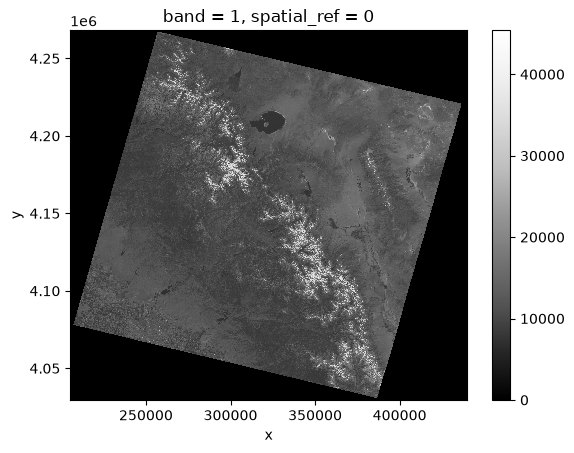

In [16]:
band_red = band_red.squeeze()  # remove the band dimension

band_red.plot.imshow(cmap='Greys_r')  # plot the band using a grayscale colormap

Great: we have a working (red-band) image and we can see that it looks like the study region from the Google Maps link above, including snow-capped mountains and lakes.

There are a few things I would note about this raw image:

 - You might have found it took a few seconds to produce a map of this image. This image is _large_: specifically, 7821 x 7951 pixels, for a total of 62,184,771 (62 million) values. This iswhy the file sizes are so large, and why doing any processing takes a bit of time! This is why we like to clip our data to a region of interest.
 - Outside the bounds of the WRS grid tile, the data is not `NaN` it is simply `0`. `rioxarray` tells us this through the `_FillValue` attribute, which is `0`.
 - Our data is of `uint16` (unsigned 16-bit integer) type and values exceed 40,000: if this is surface reflectance data, what is the unit?

It is worth thinking critically about these kind of issues every time you open a new image. 

The first two issue we can solve ourselves using proper clipping and filtering. It's important that filtering takes place before we start doing any mathematical operations, because once we do this we can loose track of what our `NaN` values are. For instance, if our `NaN` values was `-9999.0` (not an uncommon choice), and we started doing multiplication or division operations, we would lose track of the real number quickly!

We can filter to `NaN` using the `where()` function with a boolean test.

In [17]:
# Keep the red band only where the values are not equal to 0 (i.e., mask out the 0 values)
band_red = band_red.where(band_red != 0)

Next, we have to resolve the problem with our data values. Our surface reflectance data should be between 0 and ~1.0, representing the proportion of incoming solar radiation (sunlight) that is reflected back towards the satellite sensor. Our level-2 data has been corrected remove the distorting effects of the Earth's atmosphere (such as scattering by gases and aerosols). 0% means all light is absorbed, and 100% means all is reflected. For technical and physical reasons, surface reflectances greater than 1.0 can occur over bright surfaces such as snow and ice.

It would make sense to store our reflectance data as `float` data  our data is (mostly) 0 and 1.0. However, a `float` is 32-bit (4 bytes per pixel), which is twice as large as the 16-bit `int` data the Landsat data comes as (2 bytes per pixel). This is twice the data! And it is mostly wasted: `float32` formats can record numbers up to approximately 3.4 $\time$ 10<sup>38</sup> to a precision of about 7 decimal digits. As we are only interested in values between 0 and 1.0! Replicate across every pixel, every tile, for every day of the 50-year Landsat programme: this is an extortionate amount of wasted storage space and file transfers.

Instead, we use our 16-bit digital number. This has a standard conversion to turn it from a large `int` to a real `float` value. For Landsat Collection 2 data, the conversion is as follows:

$$\text{Reflectance} = (\text{Digital Number} \times 0.0000275) - 0.2$$

This process is done for a number of data sources, but exactly how will vary between satellites and missions. The European Sentinel-2 programme simply divides by 10,000 - much easier to remember!

Anyway, let's convert to real reflectances:

In [18]:
band_red_sr = (band_red * 0.0000275) - 0.2  # convert to surface reflectance

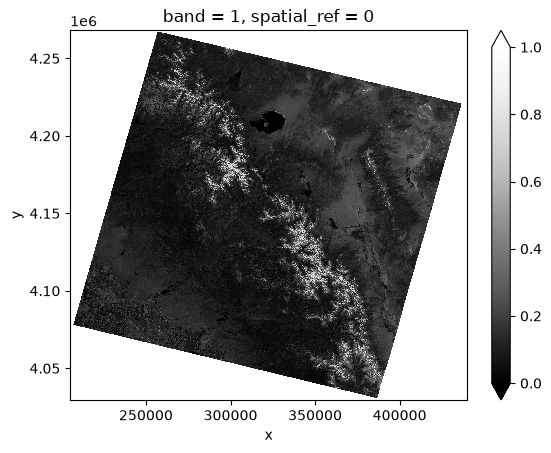

In [20]:
band_red_sr.plot.imshow(cmap='Greys_r', vmin=0, vmax=1)  # plot the surface reflectance band using a grayscale colormap

TODO - EXPLORE VALUES LESS THAN 0 IN THIS IMAGE

Great - now our data is properly scaled between (approximately) 0 and 1.



## Building a multispectral image